# Lab: RNN-Based Text Classification (IMDB Sentiment)
**Course:** Artificial Neural Networks and Deep Learning

**Aim:** Implement a SimpleRNN classifier in TensorFlow/Keras for binary sentiment classification on the IMDB reviews dataset and study the effect of hyperparameters.

In [3]:
import time, random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

# Fix seeds so the results are reproducible
SEED = 42
random.seed(SEED); np.random.seed(SEED); tf.random.set_seed(SEED)

VOCAB_SIZE = 10000   # keep the 10,000 most frequent words
MAX_LEN = 200        # every review is padded/truncated to 200 tokens
print('TensorFlow', tf.__version__)

TensorFlow 2.21.0


## Task 1 – Load and Explore the Dataset

In [4]:
(x_train_raw, y_train), (x_test_raw, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

print('Number of training samples :', len(x_train_raw))
print('Number of testing samples  :', len(x_test_raw))
print('Shape of training data     :', x_train_raw.shape, '(each review is a list of word indices)')
print('Shape of testing data      :', x_test_raw.shape)
print('Training labels shape      :', y_train.shape)
print()
print('Training  -> Positive:', int((y_train == 1).sum()), '| Negative:', int((y_train == 0).sum()))
print('Testing   -> Positive:', int((y_test == 1).sum()),  '| Negative:', int((y_test == 0).sum()))

lens = [len(r) for r in x_train_raw]
print(f'\nReview length: min={min(lens)}, max={max(lens)}, mean={np.mean(lens):.1f}, median={np.median(lens):.0f}')
print('Sample review (first 20 indices):', x_train_raw[0][:20])

Number of training samples : 25000
Number of testing samples  : 25000
Shape of training data     : (25000,) (each review is a list of word indices)
Shape of testing data      : (25000,)
Training labels shape      : (25000,)

Training  -> Positive: 12500 | Negative: 12500
Testing   -> Positive: 12500 | Negative: 12500

Review length: min=11, max=2494, mean=238.7, median=178
Sample review (first 20 indices): [1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4, 173, 36, 256, 5, 25]


## Task 2 – Data Preprocessing
The vocabulary was already limited to the 10,000 most frequent words by `num_words=10000` (rarer words become the OOV index 2). Reviews are already integer sequences; we now pad (with zeros, at the front) or truncate (keeping the last 200 tokens) so that all have length 200.

In [5]:
x_train = pad_sequences(x_train_raw, maxlen=MAX_LEN, padding='pre', truncating='pre')
x_test  = pad_sequences(x_test_raw,  maxlen=MAX_LEN, padding='pre', truncating='pre')

print('Final x_train shape:', x_train.shape)
print('Final x_test  shape:', x_test.shape)
print('y_train shape      :', y_train.shape, '| y_test shape:', y_test.shape)
print('All reviews length 200?', all(len(r) == MAX_LEN for r in x_train))
print('\nFirst padded review:\n', x_train[0])

Final x_train shape: (25000, 200)
Final x_test  shape: (25000, 200)
y_train shape      : (25000,) | y_test shape: (25000,)
All reviews length 200? True

First padded review:
 [   5   25  100   43  838  112   50  670    2    9   35  480  284    5
  150    4  172  112  167    2  336  385   39    4  172 4536 1111   17
  546   38   13  447    4  192   50   16    6  147 2025   19   14   22
    4 1920 4613  469    4   22   71   87   12   16   43  530   38   76
   15   13 1247    4   22   17  515   17   12   16  626   18    2    5
   62  386   12    8  316    8  106    5    4 2223 5244   16  480   66
 3785   33    4  130   12   16   38  619    5   25  124   51   36  135
   48   25 1415   33    6   22   12  215   28   77   52    5   14  407
   16   82    2    8    4  107  117 5952   15  256    4    2    7 3766
    5  723   36   71   43  530  476   26  400  317   46    7    4    2
 1029   13  104   88    4  381   15  297   98   32 2071   56   26  141
    6  194 7486   18    4  226   22   21  13

## Task 3 – Build the RNN Classifier
Architecture: `Input → Embedding(128) → SimpleRNN(64) → Dense(sigmoid)`. A small helper builds the model so it can be reused in the experiments.

In [6]:
def build_rnn(units=64, two_layer=False, embed_dim=128):
    layer_list = [layers.Input(shape=(MAX_LEN,)),
                  layers.Embedding(VOCAB_SIZE, embed_dim)]
    if two_layer:
        # return_sequences=True passes the hidden state of EVERY timestep to the next RNN
        layer_list.append(layers.SimpleRNN(units, return_sequences=True))
    layer_list.append(layers.SimpleRNN(units))
    layer_list.append(layers.Dense(1, activation='sigmoid'))
    return models.Sequential(layer_list)

model = build_rnn(64)
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 64)             │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,292,417 (4.93 MB)

 Trainable params: 1,292,417 (4.93 MB)

 Non-trainable params: 0 (0.00 B)

## Task 4 – Compile and Train
Adam optimizer, binary cross-entropy loss, accuracy metric, batch size 64, 20% validation split, 5 epochs.

In [7]:
def train_model(units=64, epochs=5, batch_size=64, two_layer=False, verbose=2):
    """Build, compile, train and evaluate a model. Returns model, history, test metrics, train time."""
    tf.keras.backend.clear_session()
    tf.random.set_seed(SEED)
    m = build_rnn(units, two_layer)
    m.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
    t0 = time.time()
    h = m.fit(x_train, y_train, epochs=epochs, batch_size=batch_size,
              validation_split=0.2, verbose=verbose)
    train_time = time.time() - t0
    test_loss, test_acc = m.evaluate(x_test, y_test, verbose=0)
    return m, h, test_loss, test_acc, train_time

model, history, test_loss, test_acc, base_time = train_model(units=64, epochs=5, batch_size=64)

Epoch 1/5
313/313 - 8s - 27ms/step - accuracy: 0.6952 - loss: 0.5619 - val_accuracy: 0.8006 - val_loss: 0.4306
Epoch 2/5
313/313 - 8s - 25ms/step - accuracy: 0.8396 - loss: 0.3768 - val_accuracy: 0.7932 - val_loss: 0.4452
Epoch 3/5
313/313 - 8s - 26ms/step - accuracy: 0.8188 - loss: 0.3925 - val_accuracy: 0.5868 - val_loss: 0.7246
Epoch 4/5
313/313 - 8s - 26ms/step - accuracy: 0.7962 - loss: 0.4346 - val_accuracy: 0.6372 - val_loss: 0.6351
Epoch 5/5
313/313 - 8s - 26ms/step - accuracy: 0.8726 - loss: 0.2967 - val_accuracy: 0.7126 - val_loss: 0.7045


In [8]:
hist_df = pd.DataFrame(history.history).rename(columns={
    'accuracy': 'Training Accuracy', 'val_accuracy': 'Validation Accuracy',
    'loss': 'Training Loss', 'val_loss': 'Validation Loss'})
hist_df.index = range(1, len(hist_df) + 1)
hist_df.index.name = 'epoch'
hist_df[['Training Accuracy', 'Validation Accuracy', 'Training Loss', 'Validation Loss']].round(4)

,Training Accuracy,Validation Accuracy,Training Loss,Validation Loss
epoch,,,,
1,0.6952,0.8006,0.5619,0.4306
2,0.8396,0.7932,0.3768,0.4452
3,0.8188,0.5868,0.3925,0.7246
4,0.7962,0.6372,0.4346,0.6351
5,0.8726,0.7126,0.2967,0.7045


## Task 5 – Evaluate the Model

In [9]:
print(f'Test loss    : {test_loss:.4f}')
print(f'Test accuracy: {test_acc:.4f}')
print(f'Final training accuracy  : {history.history["accuracy"][-1]:.4f}')
print(f'Final validation accuracy: {history.history["val_accuracy"][-1]:.4f}')

Test loss    : 0.7196
Test accuracy: 0.7110
Final training accuracy  : 0.8726
Final validation accuracy: 0.7126


**Q1. Final test accuracy?** The SimpleRNN (64 units, 5 epochs, batch 64) reaches a test accuracy of **71.10 %** (test loss 0.7196).

**Q2. Is test accuracy higher or lower than training accuracy?** It is **lower**: final training accuracy is 87.26 % against 71.10 % on the test set (validation 71.26 %). The model has optimised its weights on the training reviews, so it partly memorises them (1.29 M parameters, mostly in the embedding), while the test reviews are unseen. The train–test gap of about 16 points is a sign of overfitting. Validation and test accuracy agree closely, which shows the validation split is a fair estimate of generalisation.

## Task 6 – Performance Visualization

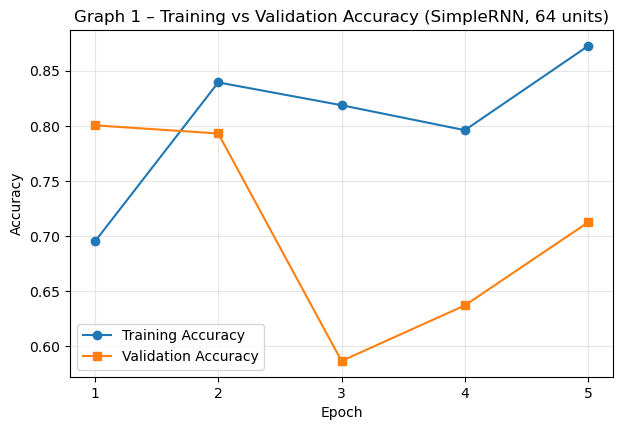

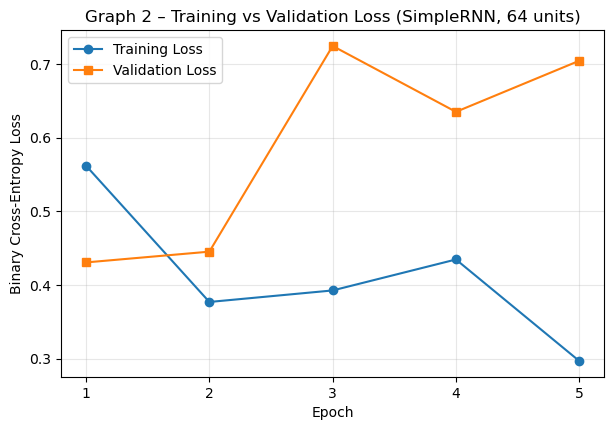

In [10]:
ep = range(1, len(history.history['accuracy']) + 1)

plt.figure(figsize=(7, 4.5))
plt.plot(ep, history.history['accuracy'], 'o-', label='Training Accuracy')
plt.plot(ep, history.history['val_accuracy'], 's-', label='Validation Accuracy')
plt.title('Graph 1 – Training vs Validation Accuracy (SimpleRNN, 64 units)')
plt.xlabel('Epoch'); plt.ylabel('Accuracy'); plt.xticks(list(ep)); plt.grid(alpha=.3); plt.legend()
plt.show()

plt.figure(figsize=(7, 4.5))
plt.plot(ep, history.history['loss'], 'o-', label='Training Loss')
plt.plot(ep, history.history['val_loss'], 's-', label='Validation Loss')
plt.title('Graph 2 – Training vs Validation Loss (SimpleRNN, 64 units)')
plt.xlabel('Epoch'); plt.ylabel('Binary Cross-Entropy Loss'); plt.xticks(list(ep)); plt.grid(alpha=.3); plt.legend()
plt.show()

### Interpretation of the graphs
**Graph 1 (accuracy).** Training accuracy rises overall (69.5 % → 87.3 %) but not smoothly: it dips in epochs 3–4. Validation accuracy peaks at 80.1 % in epoch 1, then drops sharply to 58.7 % in epoch 3 and only partly recovers to 71.3 %. The gap between the curves widens, which indicates overfitting.

**Graph 2 (loss).** Training loss falls from 0.56 to 0.30 while validation loss is lowest at epoch 1 (0.43) and rises to about 0.70 by epoch 5. Diverging training and validation loss confirms overfitting. The jagged curves reflect the instability of SimpleRNN training (exploding/vanishing gradients over 200 time steps), so the best model here is arguably the one after only 1–2 epochs.

## Task 7 – Hyperparameter Experimentation
A2, B2 and C2 are all the same configuration (64 units, 5 epochs, batch 64), so the baseline run from Task 4 is reused for them. Every other experiment is a fresh training run with the same seed. Only the parameter under study is changed.

In [11]:
results = {}   # experiment id -> dict of metrics

def run_experiment(exp_id, label, **kw):
    print(f'--- {exp_id}: {label} ---')
    m, h, tl, ta, tt = train_model(verbose=0, **kw)
    results[exp_id] = dict(Parameter=label,
                           train_acc=h.history['accuracy'][-1],
                           val_acc=h.history['val_accuracy'][-1],
                           test_acc=ta, time=tt)
    r = results[exp_id]
    print(f"train={r['train_acc']:.4f}  val={r['val_acc']:.4f}  test={r['test_acc']:.4f}  ({tt:.0f}s)")

# Baseline (64 units, 5 epochs, batch 64) reused for A2 / B2 / C2
results_base = dict(train_acc=history.history['accuracy'][-1], val_acc=history.history['val_accuracy'][-1],
                    test_acc=test_acc, time=base_time)
for eid, lab in [('A2', 'RNN = 64'), ('B2', 'Epochs = 5'), ('C2', 'Batch = 64')]:
    results[eid] = dict(Parameter=lab, **results_base)

# Experiment A – RNN units
run_experiment('A1', 'RNN = 32',  units=32)
run_experiment('A3', 'RNN = 128', units=128)

--- A1: RNN = 32 ---
train=0.9886  val=0.7932  test=0.7848  (31s)
--- A3: RNN = 128 ---
train=0.8116  val=0.7074  test=0.7070  (86s)


In [12]:
# Experiment B – number of epochs
run_experiment('B1', 'Epochs = 3',  epochs=3)
run_experiment('B3', 'Epochs = 10', epochs=10)

--- B1: Epochs = 3 ---
train=0.9067  val=0.7632  test=0.7658  (28s)
--- B3: Epochs = 10 ---
train=0.9729  val=0.7008  test=0.6999  (90s)


In [13]:
# Experiment C – batch size
run_experiment('C1', 'Batch = 32',  batch_size=32)
run_experiment('C3', 'Batch = 128', batch_size=128)

--- C1: Batch = 32 ---
train=0.8966  val=0.7322  test=0.7457  (59s)
--- C3: Batch = 128 ---
train=0.9744  val=0.7852  test=0.7821  (52s)


### Results Table

In [14]:
order = ['A1','A2','A3','B1','B2','B3','C1','C2','C3']
table = pd.DataFrame([{'Experiment': e, 'Parameter': results[e]['Parameter'],
                       'Training Accuracy': round(results[e]['train_acc'], 4),
                       'Validation Accuracy': round(results[e]['val_acc'], 4),
                       'Test Accuracy': round(results[e]['test_acc'], 4),
                       'Train Time (s)': round(results[e]['time'])} for e in order])
table

,Experiment,Parameter,Training Accuracy,Validation Accuracy,Test Accuracy,Train Time (s)
0,A1,RNN = 32,0.9886,0.7932,0.7848,31
1,A2,RNN = 64,0.8726,0.7126,0.7110,41
2,A3,RNN = 128,0.8116,0.7074,0.7070,86
3,B1,Epochs = 3,0.9067,0.7632,0.7658,28
4,B2,Epochs = 5,0.8726,0.7126,0.7110,41
5,B3,Epochs = 10,0.9729,0.7008,0.6999,90
6,C1,Batch = 32,0.8966,0.7322,0.7457,59
7,C2,Batch = 64,0.8726,0.7126,0.7110,41
8,C3,Batch = 128,0.9744,0.7852,0.7821,52


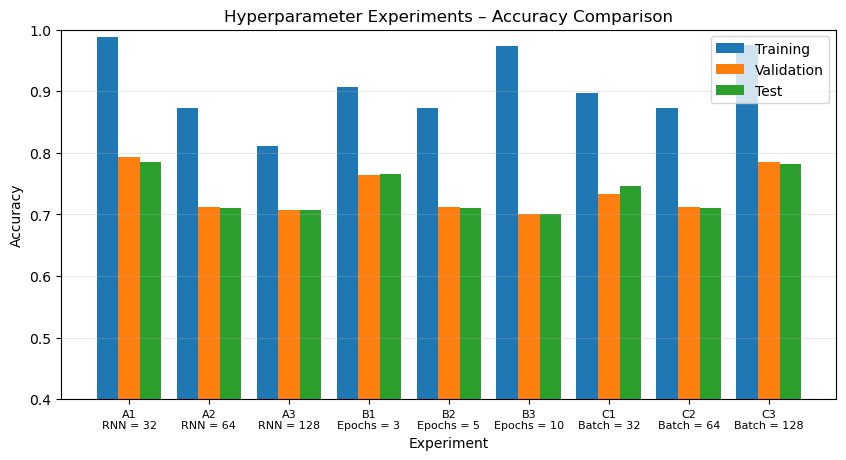

In [15]:
# Bar chart comparing the nine experiments
x = np.arange(len(order)); w = 0.27
plt.figure(figsize=(10, 4.8))
plt.bar(x - w, [results[e]['train_acc'] for e in order], w, label='Training')
plt.bar(x,     [results[e]['val_acc']   for e in order], w, label='Validation')
plt.bar(x + w, [results[e]['test_acc']  for e in order], w, label='Test')
plt.xticks(x, [f"{e}\n{results[e]['Parameter']}" for e in order], fontsize=8)
plt.ylim(0.4, 1.0); plt.title('Hyperparameter Experiments – Accuracy Comparison')
plt.xlabel('Experiment'); plt.ylabel('Accuracy'); plt.legend(); plt.grid(axis='y', alpha=.3)
plt.show()

### Explanation of the experimental results
All runs use the same seed, but SimpleRNN training is very noisy, so differences of a few points should be read as trends rather than exact effects.

**Experiment A – RNN units.** 32 units gave the best test accuracy (78.48 %), 64 units 71.10 % and 128 units 70.70 %. More units did **not** help. Larger layers have more parameters to overfit and are harder for a SimpleRNN to train. They also take longer (31 s, 41 s, 79 s).

**Experiment B – epochs.** 3 epochs gave 76.58 % test accuracy, 5 epochs 71.10 % and 10 epochs 69.99 %. Training accuracy is highest at 10 epochs (97.29 %) while validation/test accuracy is lowest, i.e. longer training mainly increases overfitting. Training for fewer epochs (or early stopping) is better here.

**Experiment C – batch size.** Batch 128 gave the best test accuracy (78.21 %), then batch 32 (74.57 %) and batch 64 (71.10 %). Larger batches were faster per epoch (43 s vs 59 s for batch 32) and gave smoother gradient estimates, which helps an unstable RNN. The non-monotonic ordering shows the run-to-run variance.

**Best configuration observed:** 32 RNN units (78.48 % test accuracy), closely followed by batch size 128 (78.21 %).

## Task 8 – Text Prediction
`predict_review` converts raw text to the same integer encoding used by `imdb.load_data` (word index shifted by 3 because indices 0–3 are reserved for padding/start/OOV), pads to 200 and runs the model. A probability ≥ 0.5 means Positive.

In [16]:
word_index = imdb.get_word_index()

def encode_review(text):
    tokens = text.lower().replace('.', ' ').replace(',', ' ').replace('!', ' ').replace('?', ' ').replace('\'', '').split()
    seq = [1]                                   # 1 = start-of-sequence token, as in the dataset
    for w in tokens:
        idx = word_index.get(w)
        seq.append(idx + 3 if (idx is not None and idx + 3 < VOCAB_SIZE) else 2)   # 2 = OOV
    return pad_sequences([seq], maxlen=MAX_LEN, padding='pre', truncating='pre')

def predict_review(text, mdl=None):
    """Return (sentiment label, probability of positive)."""
    mdl = mdl or model
    p = float(mdl.predict(encode_review(text), verbose=0)[0][0])
    return ('Positive' if p >= 0.5 else 'Negative'), p

In [17]:
test_reviews = [
    ("This movie was absolutely wonderful. The acting was brilliant and the story kept me hooked till the very end.", "Positive"),
    ("Terrible film. The plot made no sense, the acting was awful and I wasted two hours of my life.", "Negative"),
    ("A heartwarming and beautiful story with great performances. I loved every minute and would happily watch it again.", "Positive"),
    ("Boring, predictable and way too long. The characters were dull and I almost fell asleep.", "Negative"),
    ("One of the best movies I have seen this year, a fantastic cast and an excellent script.", "Positive"),
]
rows = []
for i, (txt, exp) in enumerate(test_reviews, 1):
    label, p = predict_review(txt)
    rows.append({'Review': f'Review {i}', 'Text': txt[:60] + '...', 'Expected Sentiment': exp,
                 'Predicted Sentiment': label, 'Probability (Positive)': round(p, 4),
                 'Correct': '✓' if label == exp else '✗'})
pd.DataFrame(rows)

,Review,Text,Expected Sentiment,Predicted Sentiment,Probability (Positive),Correct
0,Review 1,This movie was absolutely wonderful. The actin...,Positive,Positive,0.9710,✓
1,Review 2,"Terrible film. The plot made no sense, the act...",Negative,Negative,0.0415,✓
2,Review 3,A heartwarming and beautiful story with great ...,Positive,Positive,0.8352,✓
3,Review 4,"Boring, predictable and way too long. The char...",Negative,Negative,0.0141,✓
4,Review 5,"One of the best movies I have seen this year, ...",Positive,Positive,0.9755,✓


All five hand-written reviews were classified correctly, with confident probabilities (0.97, 0.04, 0.84, 0.01, 0.98). These reviews contain strongly polarised words ("wonderful", "terrible", "boring"), which are easy cases. With ~71 % test accuracy, the model would fail more often on sarcasm, mixed reviews or negation.

## Task 9 – Challenge Activity: Two-Layer RNN
`Embedding → SimpleRNN(64, return_sequences=True) → SimpleRNN(64) → Dense`, trained with the same settings as the baseline.

In [18]:
model2, hist2, tl2, ta2, time2 = train_model(units=64, epochs=5, batch_size=64, two_layer=True)
model2.summary()
print(f'\nTwo-layer  -> test loss {tl2:.4f}, test accuracy {ta2:.4f}, train time {time2:.0f}s')
print(f'Single-layer -> test loss {test_loss:.4f}, test accuracy {test_acc:.4f}, train time {base_time:.0f}s')

Epoch 1/5
313/313 - 16s - 50ms/step - accuracy: 0.6682 - loss: 0.5806 - val_accuracy: 0.6720 - val_loss: 0.5987
Epoch 2/5
313/313 - 15s - 47ms/step - accuracy: 0.8234 - loss: 0.3943 - val_accuracy: 0.7974 - val_loss: 0.4933
Epoch 3/5
313/313 - 14s - 46ms/step - accuracy: 0.9249 - loss: 0.1917 - val_accuracy: 0.7156 - val_loss: 0.6907
Epoch 4/5
313/313 - 14s - 46ms/step - accuracy: 0.9630 - loss: 0.1033 - val_accuracy: 0.7174 - val_loss: 0.9009
Epoch 5/5
313/313 - 15s - 47ms/step - accuracy: 0.9695 - loss: 0.0858 - val_accuracy: 0.7004 - val_loss: 0.9514


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 200, 128)       │     1,280,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 200, 64)        │        12,352 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn_1 (SimpleRNN)        │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,902,021 (14.89 MB)

 Trainable params: 1,300,673 (4.96 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 2,601,348 (9.92 MB)


Two-layer  -> test loss 0.9862, test accuracy 0.6950, train time 73s
Single-layer -> test loss 0.7196, test accuracy 0.7110, train time 41s


In [19]:
# Show what return_sequences changes: the output shape of the first RNN layer
print('return_sequences=False output:', layers.SimpleRNN(64)(tf.zeros((1, MAX_LEN, 128))).shape)
print('return_sequences=True  output:', layers.SimpleRNN(64, return_sequences=True)(tf.zeros((1, MAX_LEN, 128))).shape)

cmp = pd.DataFrame({
    'Model': ['Single-layer RNN', 'Two-layer RNN'],
    'Parameters': [model.count_params(), model2.count_params()],
    'Training Accuracy': [history.history['accuracy'][-1], hist2.history['accuracy'][-1]],
    'Validation Accuracy': [history.history['val_accuracy'][-1], hist2.history['val_accuracy'][-1]],
    'Test Accuracy': [test_acc, ta2],
    'Train Time (s)': [base_time, time2]}).round(4)
cmp

return_sequences=False output: (1, 64)
return_sequences=True  output: (1, 200, 64)


,Model,Parameters,Training Accuracy,Validation Accuracy,Test Accuracy,Train Time (s)
0,Single-layer RNN,1292417,0.8726,0.7126,0.711,40.8751
1,Two-layer RNN,1300673,0.9695,0.7004,0.695,73.3559


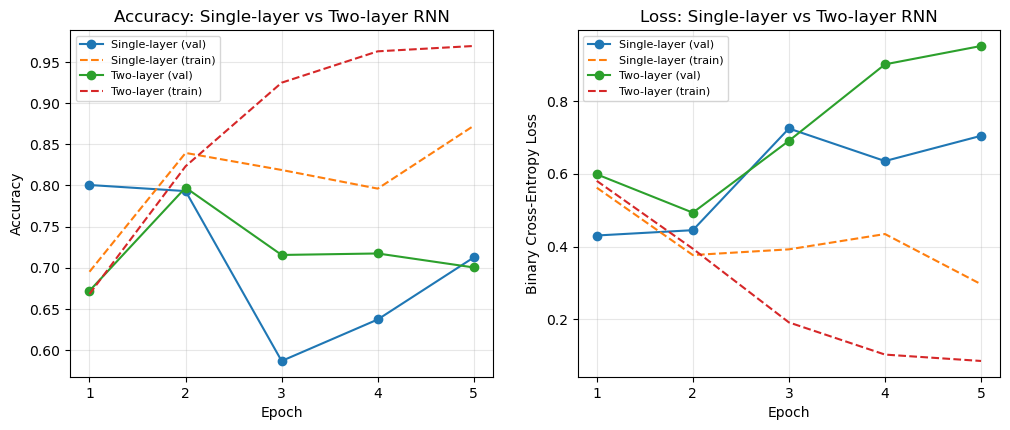

In [20]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
for h, name in [(history, 'Single-layer'), (hist2, 'Two-layer')]:
    e = range(1, 6)
    ax[0].plot(e, h.history['val_accuracy'], 'o-', label=f'{name} (val)')
    ax[0].plot(e, h.history['accuracy'], '--', label=f'{name} (train)')
    ax[1].plot(e, h.history['val_loss'], 'o-', label=f'{name} (val)')
    ax[1].plot(e, h.history['loss'], '--', label=f'{name} (train)')
ax[0].set_title('Accuracy: Single-layer vs Two-layer RNN'); ax[1].set_title('Loss: Single-layer vs Two-layer RNN')
ax[0].set_ylabel('Accuracy'); ax[1].set_ylabel('Binary Cross-Entropy Loss')
for a in ax: a.set_xlabel('Epoch'); a.set_xticks(range(1, 6)); a.grid(alpha=.3); a.legend(fontsize=8)
plt.show()

### Challenge analysis: single-layer vs two-layer RNN
| | Single-layer | Two-layer |
|---|---|---|
| Test accuracy | 71.10 % | 69.50 % |
| Training accuracy | 87.26 % | 96.95 % |
| Validation accuracy | 71.26 % | 70.04 % |
| Test loss | 0.7196 | 0.9862 |
| Training time | 41 s | 73 s |

1. **Better test accuracy:** the single-layer model (71.10 % vs 69.50 %), and it also has the lower test loss.
2. **Longer to train:** the two-layer model (73 s vs 41 s), because the second RNN must process all 200 time steps of the first layer's output.
3. **Does another layer always help?** No. The deeper model fit the training data much better (96.95 %) but generalised slightly worse (validation loss climbs to 0.95), i.e. more overfitting and harder optimisation. Extra depth only helps if the task needs it and the model is regularised and trained stably.
4. **Purpose of `return_sequences=True`:** by default an RNN returns only the hidden state of the *last* time step, shape `(batch, units)`. With `return_sequences=True` it returns the hidden state at *every* time step, shape `(batch, 200, units)` (shown in the cell above). A following RNN layer needs a sequence as input, so every RNN layer except the last must set it to `True`.

## Conclusion
In this lab I built a SimpleRNN (Embedding → SimpleRNN → Dense) for IMDB sentiment classification and learned how padding, embeddings and a sigmoid/binary cross-entropy output fit together. The baseline model (64 units, 5 epochs, batch 64) reached 71.10 % test accuracy, but its training accuracy of 87.26 % and noisy, diverging validation curves showed overfitting and unstable training. The best hyperparameters were 32 RNN units (78.48 % test accuracy) and a batch size of 128 (78.21 %). Increasing the units or the epochs did not improve performance; 128 units and 10 epochs both gave the lowest test accuracy (about 70 %) while taking longest to train. A second RNN layer raised training accuracy to 96.95 % but lowered test accuracy to 69.50 % and nearly doubled training time. The main limitations are the vanishing gradient over 200 steps, which limits long-range context, the strong overfitting, and results that vary between runs. LSTM or GRU layers with gating, plus dropout and early stopping, should handle long reviews better and give higher, more stable accuracy.